# 04 — First-batch baselines and MLflow
Train on the patient-separated training partition. Inspect train, validation and test metrics; these exploratory test results do not select the pipeline champion. Repeatedly inspected test data is not an independent final evaluation.


In [1]:
%matplotlib inline

In [2]:
import sys
from pathlib import Path
project = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

import os
from io import BytesIO
import mlflow
import mlflow.sklearn
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay


## Functions: settings
This is a copy; edit the source in 05_pipeline_walkthrough.ipynb. Run the cells in order. After saving edits in the source notebooks, run the synchronization command described in the README.

In [3]:
import os
from urllib.parse import quote_plus


In [4]:
def s3_client():
    import boto3
    return boto3.client('s3', endpoint_url=os.getenv('S3_ENDPOINT_URL','http://minio.mlops-project.svc.cluster.local:9000'), region_name='us-east-1', aws_access_key_id=os.environ['AWS_ACCESS_KEY_ID'], aws_secret_access_key=os.environ['AWS_SECRET_ACCESS_KEY'])


## Functions: preprocessing
This is a copy; edit the source in 03_preprocessing.ipynb. Run the cells in order. After saving edits in the source notebooks, run the synchronization command described in the README.

In [5]:
import hashlib
import numpy as np
import pandas as pd
NUMERIC_FEATURES = (
    'time_in_hospital', 'num_lab_procedures', 'num_procedures',
    'num_medications', 'number_outpatient', 'number_emergency',
    'number_inpatient', 'number_diagnoses',
)
SPLIT_STRATEGY = 'patient_nbr_sha256_70_15_15'


In [6]:
def split_for_patient(patient_id):
    value = int(hashlib.sha256(str(int(patient_id)).encode()).hexdigest()[:12], 16) % 10000
    return 'train' if value < 7000 else ('validation' if value < 8500 else 'test')


In [7]:
def normalize_features(features):
    """Keep categorical columns categorical, even when an entire batch is missing."""
    result = features.copy()
    result = result.mask(result.eq('?'))
    for column in result:
        if column in NUMERIC_FEATURES:
            result[column] = pd.to_numeric(result[column], errors='coerce').astype('float64')
        else:
            result[column] = result[column].map(
                lambda value: str(value) if pd.notna(value) else np.nan
            ).astype(object)
    return result


In [8]:
def prepare_records(df):
    required = {'encounter_id', 'patient_nbr', 'readmitted'}
    if not required.issubset(df.columns):
        raise ValueError(f'Missing columns: {required - set(df.columns)}')
    df = df.copy().reset_index(drop=True)
    df = df.mask(df.eq('?'))
    if df[['encounter_id', 'patient_nbr', 'readmitted']].isna().any().any():
        raise ValueError('Encounter ID, patient ID and readmission label are required')
    unexpected = set(df['readmitted'].unique()) - {'NO', '>30', '<30'}
    if unexpected:
        raise ValueError(f'Unexpected readmission labels: {unexpected}')
    df['target'] = df['readmitted'].eq('<30').astype('int8')
    df['split'] = df['patient_nbr'].map(split_for_patient)
    excluded = {'encounter_id', 'patient_nbr', 'readmitted', 'target', 'split', 'discharge_disposition_id'}
    features = normalize_features(df.drop(columns=[c for c in excluded if c in df.columns]))
    return df[['encounter_id', 'patient_nbr', 'target', 'split']], features


## Functions: training
This is the editable source. Run the cells in order. After saving edits in the source notebooks, run the synchronization command described in the README.

In [9]:
import numpy as np
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, average_precision_score, confusion_matrix


In [10]:
def make_pipeline(frame,kind='logistic'):
    numbers=frame.select_dtypes(include='number').columns.tolist()
    categories=[c for c in frame.columns if c not in numbers]
    steps=[]
    if numbers: steps.append(('num',Pipeline([('fill',SimpleImputer(strategy='median',keep_empty_features=True)),('scale',StandardScaler())]),numbers))
    if categories: steps.append(('cat',Pipeline([('fill',SimpleImputer(strategy='constant',fill_value='missing',keep_empty_features=True)),('encode',OneHotEncoder(handle_unknown='ignore'))]),categories))
    prep=ColumnTransformer(steps)
    if kind not in ('logistic', 'forest'): raise ValueError(f'Unknown model: {kind}')
    model= LogisticRegression(max_iter=500,class_weight='balanced',random_state=42) if kind=='logistic' else RandomForestClassifier(n_estimators=100,min_samples_leaf=5,random_state=42,n_jobs=2,class_weight='balanced_subsample')
    return Pipeline([('preprocess',prep),('model',model)])


In [11]:
def score_predictions(y, predicted, probabilities):
    """Report counts and classification scores; undefined AUCs remain null."""
    y = np.asarray(y, dtype=int)
    predicted = np.asarray(predicted, dtype=int)
    probabilities = np.asarray(probabilities, dtype=float)
    if len(y) == 0:
        return None
    tn, fp, fn, tp = confusion_matrix(y, predicted, labels=[0, 1]).ravel()
    result = {
        'n': int(len(y)), 'positive': int((y == 1).sum()), 'negative': int((y == 0).sum()),
        'tn': int(tn), 'fp': int(fp), 'fn': int(fn), 'tp': int(tp),
        'accuracy': float(accuracy_score(y, predicted)),
        'precision': float(precision_score(y, predicted, zero_division=0)),
        'recall': float(recall_score(y, predicted, zero_division=0)),
        'f1': float(f1_score(y, predicted, zero_division=0)),
        'roc_auc': None, 'pr_auc': None,
    }
    if len(np.unique(y)) == 2:
        result['roc_auc'] = float(roc_auc_score(y, probabilities))
        # This is average precision, not trapezoidal PR-curve area.
        result['pr_auc'] = float(average_precision_score(y, probabilities))
    return result


def metrics(model, X, y):
    if len(y) == 0:
        return None
    positive_column = list(model.classes_).index(1)
    return score_predictions(y, model.predict(X), model.predict_proba(X)[:, positive_column])


In [12]:
body = s3_client().get_object(Bucket='diabetes-source', Key='batches/batch_0001.csv')['Body'].read()
data = pd.read_csv(BytesIO(body), dtype=str, keep_default_na=False)
data = data.sort_values('encounter_id', key=lambda col: pd.to_numeric(col), kind='stable').reset_index(drop=True)
meta, X = prepare_records(data)
train = meta['split'].eq('train')
valid = meta['split'].eq('validation')
masks = {'train': train, 'validation': valid, 'test': meta['split'].eq('test')}
y = meta['target']
assert meta.groupby('patient_nbr')['split'].nunique().max() == 1
display(pd.crosstab(meta['split'], y, margins=True))

target,0,1,All
split,,,
test,2115,274,2389
train,9304,1146,10450
validation,1928,233,2161
All,13347,1653,15000


## Train and compare all splits
The table includes a baseline that always predicts no readmission. Each model fits its preprocessing using training rows only. `pr_auc` is average precision.


In [13]:
models, results = {}, []
from sklearn.dummy import DummyClassifier
baseline = DummyClassifier(strategy='prior').fit(X.loc[train], y.loc[train])
for split, mask in masks.items():
    results.append({'algorithm': 'baseline_always_no', 'split': split,
                    **metrics(baseline, X.loc[mask], y.loc[mask])})
for algorithm in ('logistic', 'forest'):
    print('Training', algorithm)
    model = make_pipeline(X.loc[train], algorithm)
    model.fit(X.loc[train], y.loc[train])
    models[algorithm] = model
    for split, mask in masks.items():
        results.append({'algorithm': algorithm, 'split': split,
                        **metrics(model, X.loc[mask], y.loc[mask])})
comparison = pd.DataFrame(results)
display(comparison.set_index(['algorithm', 'split']).round(4))

Training logistic
Training forest


n  positive  negative    tn    fp    fn  \
algorithm          split                                                     
baseline_always_no train       10450      1146      9304  9304     0  1146   
                   validation   2161       233      1928  1928     0   233   
                   test         2389       274      2115  2115     0   274   
logistic           train       10450      1146      9304  6643  2661   283   
                   validation   2161       233      1928  1290   638   123   
                   test         2389       274      2115  1418   697   153   
forest             train       10450      1146      9304  8261  1043   306   
                   validation   2161       233      1928  1664   264   166   
                   test         2389       274      2115  1796   319   191   

                                tp  accuracy  precision  recall      f1  \
algorithm          split                                                  
baseline_always_no train         0    0.8903     0.0000  0.0000  0.0000   
                   validation    0    0.8922     0.0000  0.0000  0.0000   
                   test          0    0.8853     0.0000  0.0000  0.0000   
logistic           train       863    0.7183     0.2449  0.7531  0.3696   
                   validation  110    0.6478     0.1471  0.4721  0.2243   
                   test        121    0.6442     0.1479  0.4416  0.2216   
forest             train       840    0.8709     0.4461  0.7330  0.5546   
                   validation   67    0.8010     0.2024  0.2876  0.2376   
                   test         83    0.7865     0.2065  0.3029  0.2456   

                               roc_auc  pr_auc  
algorithm          split                        
baseline_always_no train        0.5000  0.1097  
                   validation   0.5000  0.1078  
                   test         0.5000  0.1147  
logistic           train        0.8071  0.3060  
                   validation   0.6100  0.1628  
                   test         0.5837  0.1532  
forest             train        0.9105  0.6090  
                   validation   0.6617  0.1938  
                   test         0.6463  0.1882

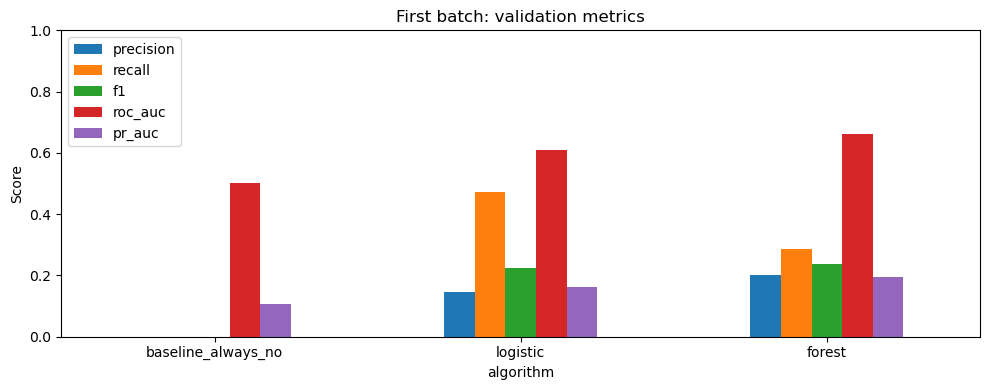

In [14]:
validation_scores = comparison[comparison['split'].eq('validation')].set_index('algorithm')
validation_scores[['precision', 'recall', 'f1', 'roc_auc', 'pr_auc']].plot.bar(figsize=(10, 4), ylim=(0, 1), rot=0)
plt.title('First batch: validation metrics'); plt.ylabel('Score'); plt.tight_layout(); plt.show()

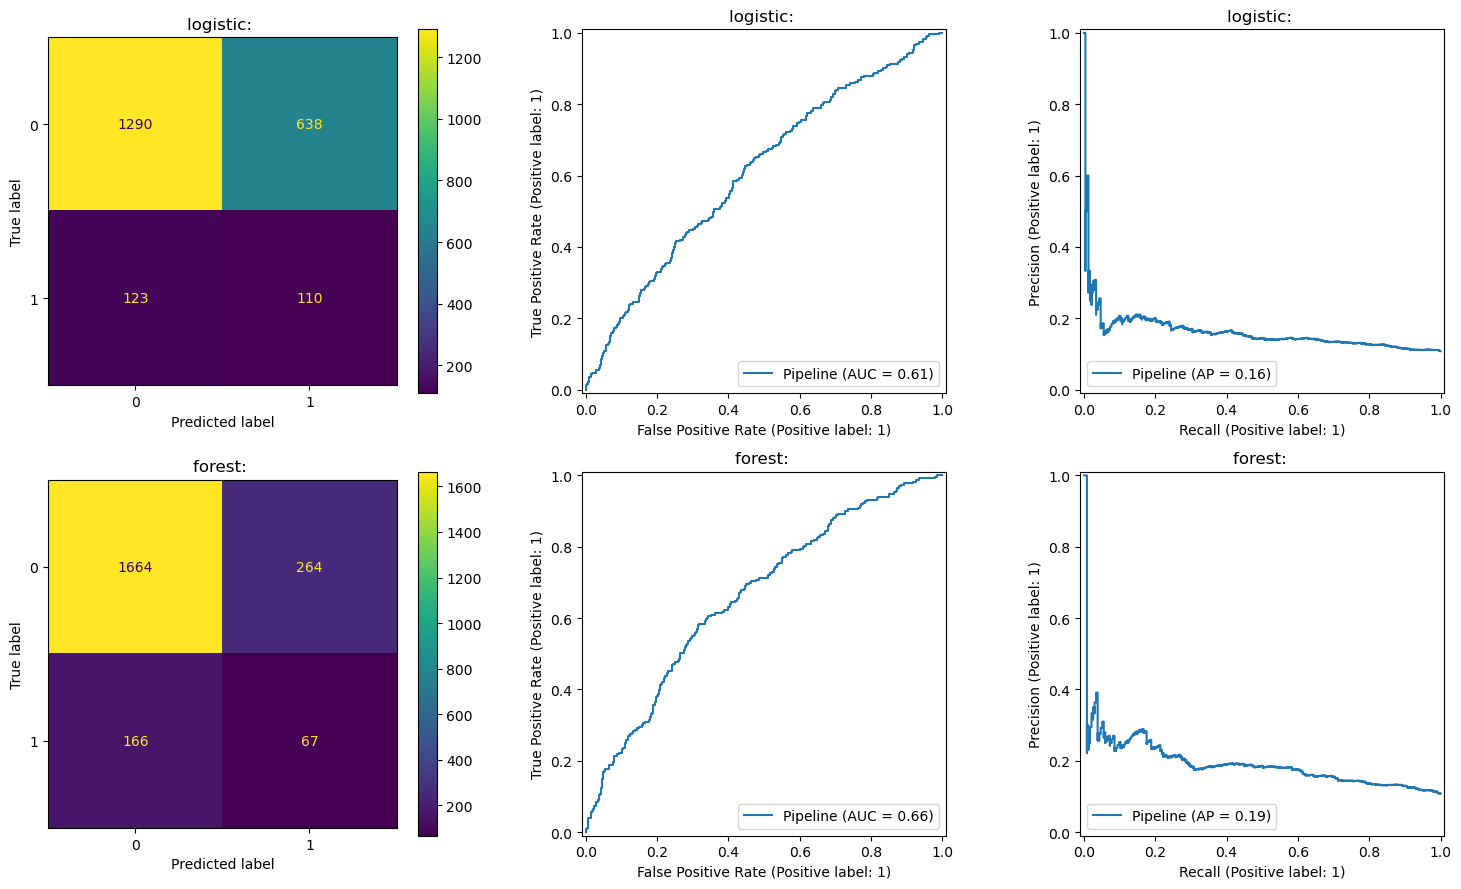

In [15]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for row, (name, model) in enumerate(models.items()):
    ConfusionMatrixDisplay.from_estimator(model, X.loc[valid], y.loc[valid], ax=axes[row, 0])
    RocCurveDisplay.from_estimator(model, X.loc[valid], y.loc[valid], ax=axes[row, 1])
    PrecisionRecallDisplay.from_estimator(model, X.loc[valid], y.loc[valid], ax=axes[row, 2])
    for ax in axes[row]: ax.set_title(f'{name}: {ax.get_title()}')
plt.tight_layout(); plt.show()

## Log development runs to MLflow
Run notebook 01 first so the artifact bucket exists. These models are trained in this notebook, so the two named `skops` types are explicitly trusted. Run this cell again only when you want new MLflow runs.

In [16]:
mlflow.set_tracking_uri(os.environ['MLFLOW_TRACKING_URI'])
experiment = mlflow.set_experiment('diabetes-first-batch')
print('Experiment:', experiment.name, 'ID:', experiment.experiment_id)
requirements = ['mlflow==3.17.2', 'scikit-learn==1.7.1', 'numpy==2.2.6',
                'pandas==2.3.1', 'skops==0.16.0']
for name, model in models.items():
    with mlflow.start_run(run_name=f'batch_0001-{name}') as run:
        mlflow.log_params({'algorithm': name, 'batch': 'batch_0001',
                           'train_rows': int(train.sum()), 'split_strategy': SPLIT_STRATEGY})
        split_scores = {}
        for split, mask in masks.items():
            split_scores[split] = metrics(model, X.loc[mask], y.loc[mask])
            mlflow.log_metrics({f'{split}_{k}': v for k, v in split_scores[split].items() if v is not None})
        mlflow.log_dict({'batch_0001': split_scores}, 'evaluation/batch_0001_metrics.json')
        fig, axes = plt.subplots(1, 3, figsize=(15, 4))
        ConfusionMatrixDisplay.from_estimator(model, X.loc[valid], y.loc[valid], ax=axes[0])
        RocCurveDisplay.from_estimator(model, X.loc[valid], y.loc[valid], ax=axes[1])
        PrecisionRecallDisplay.from_estimator(model, X.loc[valid], y.loc[valid], ax=axes[2])
        fig.tight_layout()
        mlflow.log_figure(fig, f'{name}_validation_plots.png')
        plt.close(fig)
        mlflow.sklearn.log_model(model, name='model', pip_requirements=requirements,
                                 skops_trusted_types=['numpy.dtype', 'sklearn.tree._tree.Tree'])
        print(name, 'run:', run.info.run_id)

2026/11/02 23:49:45 INFO mlflow.tracking.fluent: Experiment with name 'diabetes-first-batch' does not exist. Creating a new experiment.


Experiment: diabetes-first-batch ID: 1
logistic run: 34eb8752f7654b16975067e1b3646493
🏃 View run batch_0001-logistic at: http://mlflow-mlflow.mlops-project.svc.cluster.local:5000/#/experiments/1/runs/34eb8752f7654b16975067e1b3646493
🧪 View experiment at: http://mlflow-mlflow.mlops-project.svc.cluster.local:5000/#/experiments/1
forest run: 0e883f12a7a540639cb66ddd0594ed69
🏃 View run batch_0001-forest at: http://mlflow-mlflow.mlops-project.svc.cluster.local:5000/#/experiments/1/runs/0e883f12a7a540639cb66ddd0594ed69
🧪 View experiment at: http://mlflow-mlflow.mlops-project.svc.cluster.local:5000/#/experiments/1


logistic run: 11ed0c73591040e594d0bd2e587389d5
🏃 View run batch_0001-logistic at: http://mlflow-mlflow.mlops-project.svc.cluster.local:5000/#/experiments/1/runs/11ed0c73591040e594d0bd2e587389d5
🧪 View experiment at: http://mlflow-mlflow.mlops-project.svc.cluster.local:5000/#/experiments/1


forest run: 66f028569f69471e89ec5ce619d2bd48
🏃 View run batch_0001-forest at: http://mlflow-mlflow.mlops-project.svc.cluster.local:5000/#/experiments/1/runs/66f028569f69471e89ec5ce619d2bd48
🧪 View experiment at: http://mlflow-mlflow.mlops-project.svc.cluster.local:5000/#/experiments/1


Open the MLflow UI through the port-forward from `commands.txt`. Links printed by MLflow may use the internal Kubernetes hostname, which is accessible inside the cluster. The held-out test split is not used to pick a model here.